# Исследование объявлений о продаже квартир

В данном проекте у меня в распоряжении были данные сервиса Яндекс.Недвижимость — архив объявлений о продаже квартир в Санкт-Петербурге и соседних населённых пунктов за несколько лет. 
Бизнес задача: Научиться определять рыночную стоимость объектов недвижимости. Моя задача — установить параметры. Это позволит построить автоматизированную систему: она отследит аномалии и мошенническую деятельность. 

По каждой квартире на продажу доступны два вида данных. Первые вписаны пользователем, вторые — получены автоматически на основе картографических данных. Например, расстояние до центра, аэропорта, ближайшего парка и водоёма. 

### Открыть файл с данными и изучить общую информацию. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('real_estate_data.csv', sep='\t')

In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

Функция info() предоставляет информацию о количестве ненулевых значений, типах данных и использовании памяти для каждого столбца в датафрейме. В данном датасете можно увидеть, что присутствует две колонки с булевым типом данных, три - со строкой и остальные - количественные данные.  В ходе исследования возможно придется изменить типы тех или иных данных.

In [3]:
data.isnull().sum()

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment            20924
studio                      0
open_plan                   0
kitchen_area             2278
balcony                 11519
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000         5518
parks_nearest           15620
ponds_around3000         5518
ponds_nearest           14589
days_exposition          3181
dtype: int64

В таблице присутствует 14 столбцов, где есть пропуски. Шесть из них предположительно должны были быть заполнены самим пользователем: высота потолков, общее количество этажей в доме, жилая площадь и площадь кухни, является ли помещение апартами и есть ли там балкон. Остальные данные в датасете должны были быть заполнены автоматически. Про пропуски я напишу более подробно далее, когда приступлю к предобработке данных. 

In [4]:
data.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000.0,108.0,2019-03-07T00:00:00,3,2.70,16.0,51.0,8,NaN,...,25.0,NaN,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
1,7,3350000.0,40.4,2018-12-04T00:00:00,1,NaN,11.0,18.6,1,NaN,...,11.0,2.0,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
2,10,5196000.0,56.0,2015-08-20T00:00:00,2,NaN,5.0,34.3,4,NaN,...,8.3,0.0,Санкт-Петербург,21741.0,13933.0,1.0,90.0,2.0,574.0,558.0
3,0,64900000.0,159.0,2015-07-24T00:00:00,3,NaN,14.0,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
4,2,10000000.0,100.0,2018-06-19T00:00:00,2,3.03,14.0,32.0,13,NaN,...,41.0,NaN,Санкт-Петербург,31856.0,8098.0,2.0,112.0,1.0,48.0,121.0


In [5]:
data.columns

Index(['total_images', 'last_price', 'total_area', 'first_day_exposition',
       'rooms', 'ceiling_height', 'floors_total', 'living_area', 'floor',
       'is_apartment', 'studio', 'open_plan', 'kitchen_area', 'balcony',
       'locality_name', 'airports_nearest', 'cityCenters_nearest',
       'parks_around3000', 'parks_nearest', 'ponds_around3000',
       'ponds_nearest', 'days_exposition'],
      dtype='object')

Я использовала этот метод, чтобы посмотреть какие колонки есть в датафрейме и названы ли они без ошибок. 

array([[<Axes: title={'center': 'total_images'}>,
        <Axes: title={'center': 'last_price'}>,
        <Axes: title={'center': 'total_area'}>,
        <Axes: title={'center': 'rooms'}>],
       [<Axes: title={'center': 'ceiling_height'}>,
        <Axes: title={'center': 'floors_total'}>,
        <Axes: title={'center': 'living_area'}>,
        <Axes: title={'center': 'floor'}>],
       [<Axes: title={'center': 'kitchen_area'}>,
        <Axes: title={'center': 'balcony'}>,
        <Axes: title={'center': 'airports_nearest'}>,
        <Axes: title={'center': 'cityCenters_nearest'}>],
       [<Axes: title={'center': 'parks_around3000'}>,
        <Axes: title={'center': 'parks_nearest'}>,
        <Axes: title={'center': 'ponds_around3000'}>,
        <Axes: title={'center': 'ponds_nearest'}>],
       [<Axes: title={'center': 'days_exposition'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

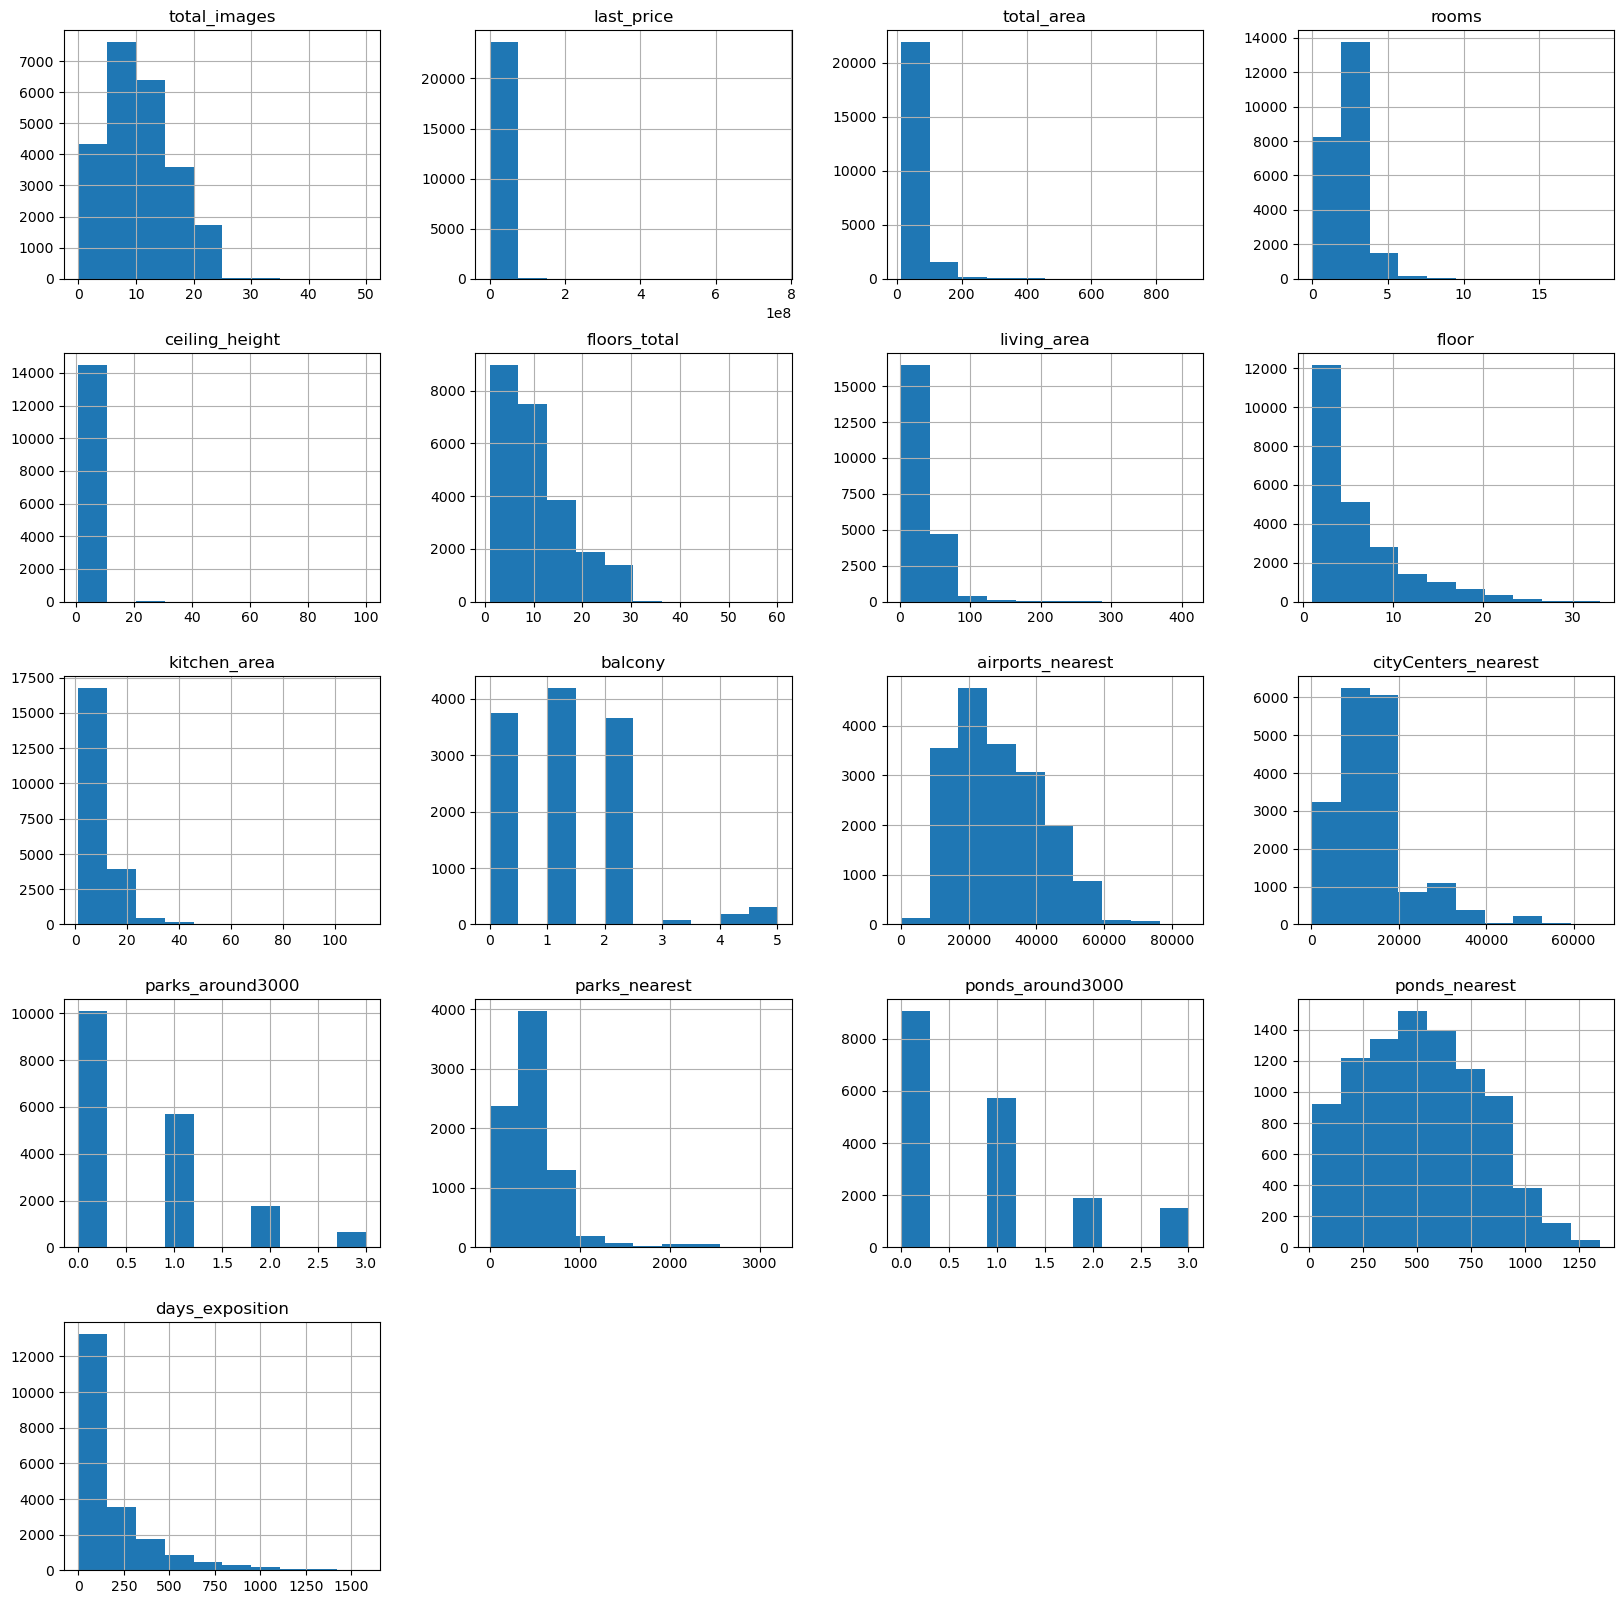

In [6]:
data.hist(figsize=(20, 20))

### Предобработка данных

1. Найти и изучить пропущенные значения в столбцах:
2. Рассмотреть типы данных в каждом столбце:
    - Найти столбцы, в которых нужно изменить тип данных.
    - Преобразовать тип данных в выбранных столбцах.
3. Изучить уникальные значения в столбце с названиями и устранить неявные дубликаты. 

In [7]:
data.isnull().sum()

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment            20924
studio                      0
open_plan                   0
kitchen_area             2278
balcony                 11519
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000         5518
parks_nearest           15620
ponds_around3000         5518
ponds_nearest           14589
days_exposition          3181
dtype: int64

В колонке про высоту потолков почти 10 тысяч пропусков. Я предполагаю, что самая вероятная причина пропусков - это то, что данные заполняли пользователи вручную и некоторые просто решили не вносить эти данные по различным причинам. При этом нельзя исключать вероятность технической ошибки, возникшей при выгрузке и/или переносе данных. 

In [8]:
data['ceiling_height'].describe()

count    14504.000000
mean         2.771499
std          1.261056
min          1.000000
25%          2.520000
50%          2.650000
75%          2.800000
max        100.000000
Name: ceiling_height, dtype: float64

Для заполнения пропусков в колонке "Высота потолков" для начала смотрю общее описание данных в таблице. Здесь видно, что максимально значение - 100 метров, что является несколько подозрительным. Поэтому я хочу построить гистрограмму, чтобы посмотреть, является ли этого единичным выбросом.

<Axes: >

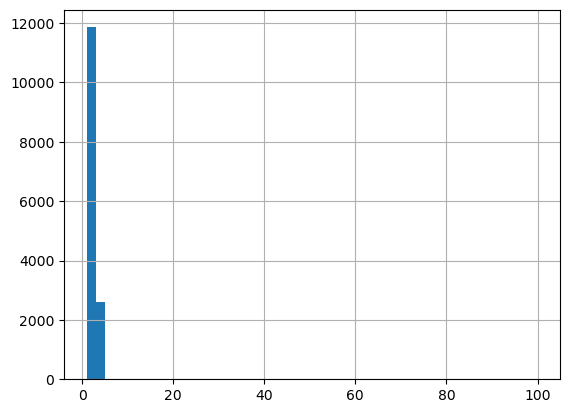

In [9]:
data['ceiling_height'].hist(bins=50)

Из гистограммы видно, что практически все данные сосредоточены в интервале от 1 до 5. Построю новую гистограмму, учитывая это.

<Axes: >

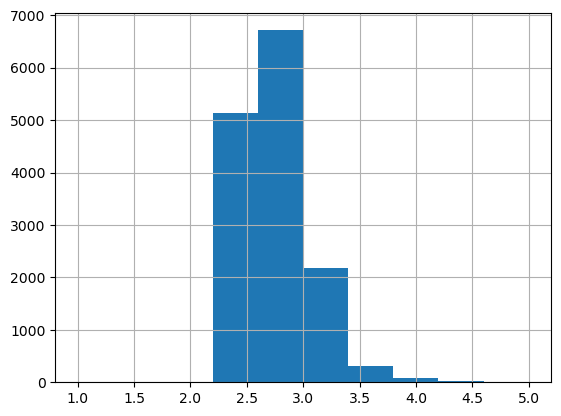

In [10]:
data['ceiling_height'].hist(bins=10, range=(1,5))

На этой гистограмме видно, что квартир у которых размер потолков меньше 2 метров очень мало, что позволяет мне ограничить выборку до интервала от 2 до 4.5 метров.

In [11]:
ceiling = data.query('2 < ceiling_height < 4.5')
ceiling['ceiling_height'].describe()

count    14441.000000
mean         2.724273
std          0.265126
min          2.200000
25%          2.520000
50%          2.650000
75%          2.800000
max          4.450000
Name: ceiling_height, dtype: float64

Объединив данные без выбросов в новую переменную, я считаю среднее арфмитическое по высоте потолков и этим значением заполняю пропуски в изначальной базе данных

In [12]:
ceiling_height_avg = ceiling['ceiling_height'].mean()
data['ceiling_height'] = data['ceiling_height'].fillna(ceiling_height_avg)

In [13]:
data['ceiling_height'].isnull().sum()

0

Дальше я буду заполнять пропуску в колонке с общим количеством этажей в доме. Здесь я также предполагаю, что причина пропусков в человеческом факторе.

Для того, чтобы заполнить пропуски в общем количестве этажей, я планирую написать функцию. Перед этим я смотрю, какое количество этажей наиболее распространеннеое в датасете. 

In [14]:
data['floors_total'].value_counts().head(15)

floors_total
5.0     5788
9.0     3761
16.0    1376
12.0    1362
4.0     1200
10.0    1174
25.0    1075
6.0      914
17.0     833
3.0      668
7.0      592
14.0     553
18.0     505
24.0     469
8.0      390
Name: count, dtype: int64

Я взяла за основу самые распространенные варианты значения данной строки, чтобы написать функцию, которая назначала бы количество общих этажей, основываясь на этаже на котором находится квартира. 

In [15]:
def assign_total_floors (row):
    floor = row['floor']
    if floor <= 5:
        return 5
    elif floor <= 9:
        return 9
    elif floor <= 16:
        return 16
    elif floor <= 25:
        return 25
    elif floor <= 30:
        return 30
    else:
        return floor

Теперь, используя эту функцию, я заполняю пропуски в таблице. 

In [16]:
data['floors_total'] = data.apply(lambda row: assign_total_floors(row) 
                                  if pd.isnull(row['floors_total']) 
                                  else row['floors_total'], axis=1)

In [17]:
data['floors_total'].isnull().sum()

0

Создаю новую колонку с коэффициентом отношения жилой площади к общей для всех доступных данных

In [18]:
data['ratio_living'] = data['living_area'] / data['total_area']

Вычисляю среднее значения коэффициента отношения

In [19]:
mean_ratio_living = data['ratio_living'].mean()
mean_ratio_living

0.5647655216993234

Заполняю пропущенные значения

In [20]:
data['living_area'].fillna(data['total_area'] * mean_ratio_living, inplace=True)

In [21]:
data['living_area'].isnull().sum()

0

Повторяю такую же операцию для площади кухни

In [22]:
data['ratio_kitchen'] = data['kitchen_area'] / data['total_area']
mean_ratio_kitchen = data['ratio_kitchen'].mean()
mean_ratio_kitchen

0.1873547387717406

In [23]:
data['kitchen_area'].fillna(data['total_area'] * mean_ratio_kitchen, inplace=True)

In [24]:
data['kitchen_area'].isnull().sum()

0

Таким образом, я заполнила все пропуски в колонках с жилой площадью и площадью кухни.

Аппарты в данном датасете - это не жилые помещения или же помещения, в которых можно жить, но нельзя прописаться. Этот пункт в объявлении должен был проставить сам арендодатель квартиры. Следовательно я предположила, что если это поле не проставлено, то квартира скорее всего не является апартами.

In [25]:
data['is_apartment'] = data['is_apartment'].fillna(value=False)

In [26]:
data['is_apartment'].isnull().sum()

0

Как упоминалось в задании: если продавец не указал число балконов, то, скорее всего, в его квартире их нет. 

In [27]:
data['balcony'] = data['balcony'].fillna(value=0)

In [28]:
data['balcony'].isnull().sum()

0

В колонке с названием населённого пункта встречается 49 пропусков. Логически заменить их не представляется возможным, поэтому я решаю удалить их.

In [29]:
data = data.dropna(subset=['locality_name'])

In [30]:
data['locality_name'].isnull().sum()

0

Вот список оставшихся колонок, в которых я еще не занималась пропусками
1. airports_nearest         5542
2. cityCenters_nearest      5519
3. parks_around3000         5518
4. parks_nearest           15620
5. ponds_around3000         5518
6. ponds_nearest           14589
7. days_exposition          3181

Все данные здесь должны были заполнятся автоматически при выгрузке базы данных. Заполнить все эти пропуски не представляется возможным, кроме колонок с количеством прудов и парков в радиусе 3 км. 
Проверяем условие, если расстояние до ближайшего парка или водоема больше трех км, то ставим 0. 

In [31]:
data['parks_around3000'] = data['parks_around3000'].fillna(0)
data['ponds_around3000'] = data['ponds_around3000'].fillna(0)

In [32]:
data.loc[(data['parks_nearest'] > 3000), 'parks_around3000'] = 0
data.loc[(data['ponds_nearest'] > 3000), 'ponds_around3000'] = 0

2. Рассмотреть типы данных в каждом столбце:
    - Найти столбцы, в которых нужно изменить тип данных.
    - Преобразовать тип данных в выбранных столбцах.

Столбцы, в которых надо изменить тип данных:
1. first_day_exposition - дата публикации объявления. Тип данных должен быть изменен на datetime.
2. is_apartment - указание на апартаменты. Тип данных должен быть изменен на bool.
3. balcony, floors_total, parks_around3000, ponds_around3000 нужно преобразовать в тип данных int.

In [33]:
data['first_day_exposition'] = pd.to_datetime(data['first_day_exposition'], format='%Y-%m-%dT%H:%M:%S')

In [34]:
data['is_apartment'] = data['is_apartment'].astype(bool)

In [35]:
data['balcony'] = data['balcony'].astype(int)

In [36]:
data['floors_total'] = data['floors_total'].astype(int)

In [37]:
data['parks_around3000'] = data['parks_around3000'].astype(int)

In [38]:
data['ponds_around3000'] = data['ponds_around3000'].astype(int)

3. Изучить уникальные значения в столбце с названиями и устранить неявные дубликаты. 

In [39]:
data['locality_name'] = (
    data['locality_name']
    .str.replace('ё', 'е')
    .replace(['городской поселок', 'коттеджный поселок', 'поселок городского типа', 'поселок при железнодорожной станции', 'поселок станции', 'деревня', 'поселок', 'садоводческое некоммерческое товарищество', 'садовое товарищество', 'село'], '', regex=True)
)
data['locality_name'] = data['locality_name'].str.strip() 

Для того чтобы убрать неявные дубликаты в столбце с названиями населенных пунктов, я убрала все обозначения типа населенного пункта и убрала пробелы в начале и конце строки.

Сейчас цена квартиры указана полностью, для упрощения работы переводим цену из целой цены в миллионах в количество миллионов. Для этого создам новую колонку.

In [40]:
data['last_price_ml'] = data['last_price'] / 1000000

### Посчитать и добавить в таблицу новые столбцы

- цена одного квадратного метра (нужно поделить стоимость объекта на его общую площадь, а затем округлить до двух знаков после запятой);
- день недели публикации объявления (0 — понедельник, 1 — вторник и так далее);
- месяц публикации объявления;
- год публикации объявления;
- тип этажа квартиры (значения — «‎первый», «последний», «другой»);
- расстояние до центра города в километрах (переведите из *м* в *км* и округлите до ближайших целых значений).

In [41]:
data['sqrm_price'] = round(data['last_price'] / data['total_area'], 2)

In [42]:
data['day_of_week'] = data['first_day_exposition'].dt.dayofweek

In [43]:
data['month'] = data['first_day_exposition'].dt.month

In [44]:
data['year'] = data['first_day_exposition'].dt.year

In [45]:
def floor_type(row):
    if row['floor'] == 1:
        return 'первый'
    elif row['floor'] == row['floors_total']:
        return 'последний'
    else:
        return 'другой'

data['floor_type'] = data.apply(floor_type, axis=1)

In [46]:
data['distance_to_center'] = round(data['cityCenters_nearest'] / 1000)

Смотрю, что все столбцы добавились корректно и значения проставлены

In [47]:
data.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,days_exposition,ratio_living,ratio_kitchen,last_price_ml,sqrm_price,day_of_week,month,year,floor_type,distance_to_center
0,20,13000000.0,108.0,2019-03-07,3,2.700000,16,51.000000,8,False,...,NaN,0.472222,0.231481,13.000,120370.37,3,3,2019,другой,16.0
1,7,3350000.0,40.4,2018-12-04,1,2.724273,11,18.600000,1,False,...,81.0,0.460396,0.272277,3.350,82920.79,1,12,2018,первый,19.0
2,10,5196000.0,56.0,2015-08-20,2,2.724273,5,34.300000,4,False,...,558.0,0.612500,0.148214,5.196,92785.71,3,8,2015,другой,14.0
3,0,64900000.0,159.0,2015-07-24,3,2.724273,14,89.797718,9,False,...,424.0,NaN,NaN,64.900,408176.10,4,7,2015,другой,7.0
4,2,10000000.0,100.0,2018-06-19,2,3.030000,14,32.000000,13,False,...,121.0,0.320000,0.410000,10.000,100000.00,1,6,2018,другой,8.0


### Провести исследовательский анализ данных

1. Изучить перечисленные ниже параметры объектов и построить отдельные гистограммы для каждого из этих параметров. В некоторых параметрах встречаются редкие и выбивающиеся значения. При построении гистограмм надо удалить их. 
    
    **Список параметров:**
    
    - общая площадь;
    - жилая площадь;
    - площадь кухни;
    - цена объекта;
    - количество комнат;
    - высота потолков;
    - тип этажа квартиры («первый», «последний», «другой»);
    - общее количество этажей в доме;
    - расстояние до центра города в метрах;
    - расстояние до ближайшего парка


Для начала строю гистограмму для столбца с общей площадью квартиры.

<Axes: >

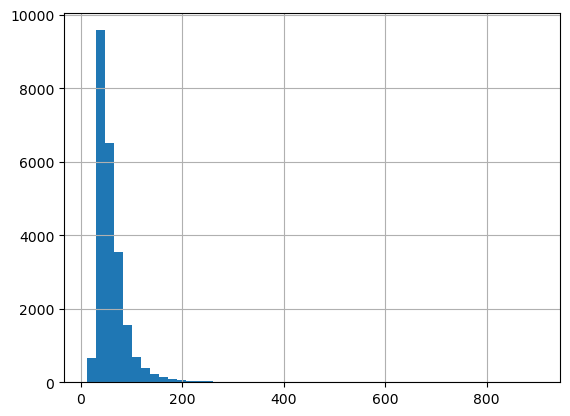

In [48]:
data['total_area'].hist(bins=50)

In [49]:
data['total_area'].describe()

count    23650.000000
mean        60.329069
std         35.661808
min         12.000000
25%         40.000000
50%         52.000000
75%         69.700000
max        900.000000
Name: total_area, dtype: float64

Из данных выше видно, что все основные значения сосредоточены в предлах от 0 до 300 квадратных метров. Однако есть выбивающиеся значения. Они могут быть реальными, а не ошибкой, однако это все равно аномальные данные и для дальнейшего исследования я решила их исключить.

In [50]:
total_area = data.query('total_area < 300')

In [51]:
total_area['total_area'].describe()

count    23587.000000
mean        59.409124
std         30.458725
min         12.000000
25%         40.000000
50%         52.000000
75%         69.300000
max        297.500000
Name: total_area, dtype: float64

Таким образом, создав новую переменную и убрав сильно выбивающиеся значения можно построить новую гистограмму.

<Axes: >

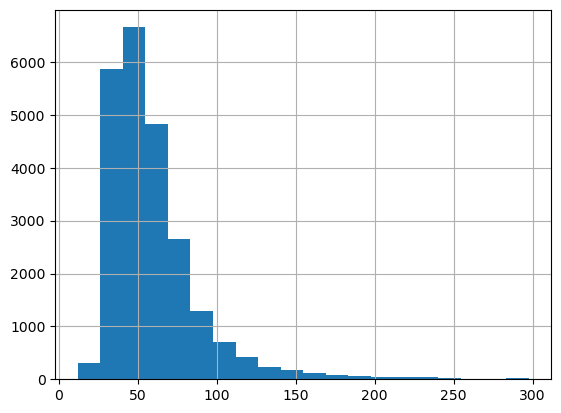

In [52]:
total_area['total_area'].hist(bins=20)

Теперь можно заметить, что в среднем общая площадь квартиры состовляет примерно 50 квадратных метров.

<Axes: >

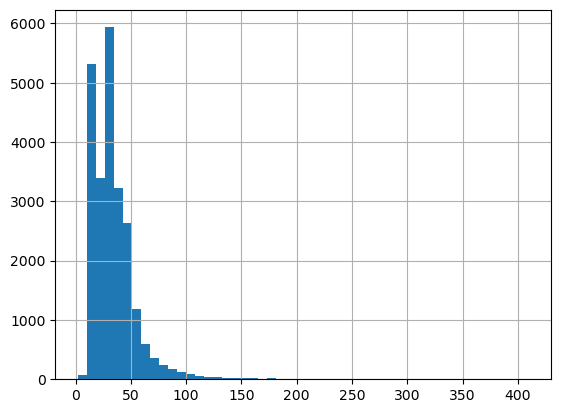

In [53]:
data['living_area'].hist(bins=50)

Теперь я смотрю гистограмму жилой площади. Из нее видно, что присутствуют выбивающиеся значения. Для этого дальше я смотрю общее описание.

In [54]:
data['living_area'].describe()

count    23650.000000
mean        34.550733
std         22.331969
min          2.000000
25%         19.000000
50%         30.000000
75%         42.093758
max        409.700000
Name: living_area, dtype: float64

Создаю новую переменную, где ограничиваю жилую площадь 150 квадратными метрами, убирая выбивающиеся значения.

In [55]:
living_area = data.query('living_area < 150')
living_area['living_area'].describe()

count    23513.000000
mean        33.595314
std         18.110669
min          2.000000
25%         19.000000
50%         30.000000
75%         42.000000
max        149.400000
Name: living_area, dtype: float64

Строю новую гистограмму

<Axes: >

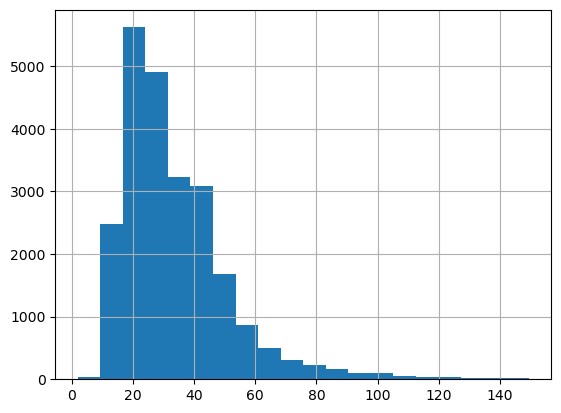

In [56]:
living_area['living_area'].hist(bins=20)

Из новой гистограммы можно сделать вывод, что самый распространенный размер жилой площади в данном датасете - 20 квадратных метров.

<Axes: >

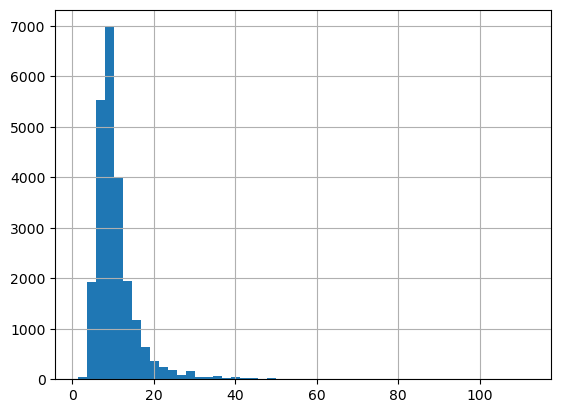

In [57]:
data['kitchen_area'].hist(bins=50)

С площадью кухни провожу те же манипуляции, что и с общей и жилой площадью.

In [58]:
data['kitchen_area'].describe()

count    23650.000000
mean        10.569111
std          6.092870
min          1.300000
25%          7.000000
50%          9.050000
75%         12.000000
max        112.000000
Name: kitchen_area, dtype: float64

In [59]:
kitchen_area = data.query('kitchen_area < 50')
kitchen_area['kitchen_area'].describe()

count    23576.000000
mean        10.400910
std          5.242476
min          1.300000
25%          7.000000
50%          9.000000
75%         12.000000
max         49.400000
Name: kitchen_area, dtype: float64

<Axes: >

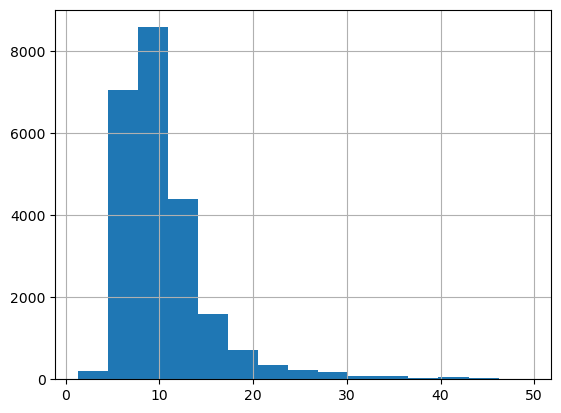

In [60]:
kitchen_area['kitchen_area'].hist(bins=15)

<Axes: >

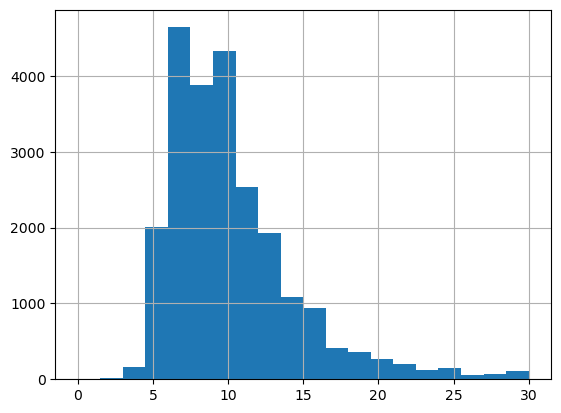

In [61]:
kitchen_area['kitchen_area'].hist(bins=20, range=(0,30))

На гистограме с размерами площади кухни есть два пика, что говорит, что в датасете больше всего квартира, где площадь кухни около 6 или 9 квадратных метров.

<Axes: >

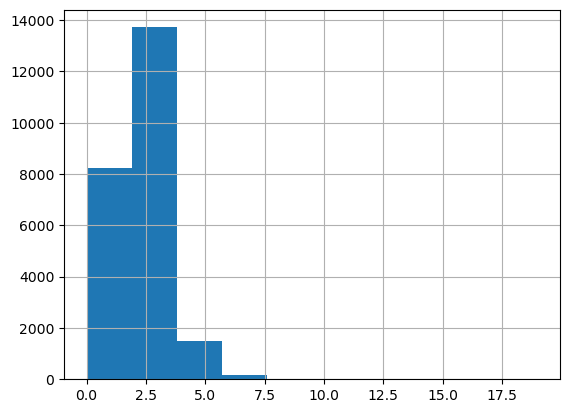

In [62]:
data['rooms'].hist(bins=10)

In [63]:
data['rooms'].describe()

count    23650.000000
mean         2.070106
std          1.078620
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         19.000000
Name: rooms, dtype: float64

Исходя из гистограммы и описания видно что есть квартиры, в которых больше 7 комнат. Это кажется аномальным, но не нереалистичным, так как такие квартиры действительно могут быть. Я хочу посмотреть много ли таких квартир и можно ли их исключить.

In [64]:
rooms_max = data.query('rooms > 7')
rooms_max

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,days_exposition,ratio_living,ratio_kitchen,last_price_ml,sqrm_price,day_of_week,month,year,floor_type,distance_to_center
648,3,17500000.0,183.7,2018-07-01,11,3.400000,7,138.800000,7,False,...,NaN,0.755580,0.072401,17.5000,95264.02,6,7,2018,последний,3.0
813,7,16500000.0,229.0,2016-02-25,8,2.724273,6,160.000000,5,False,...,806.0,0.698690,0.109170,16.5000,72052.40,3,2,2016,другой,5.0
866,5,25000000.0,363.0,2017-12-23,14,3.160000,5,222.000000,4,False,...,418.0,0.611570,0.045730,25.0000,68870.52,5,12,2017,другой,8.0
4149,6,23000000.0,272.6,2018-01-11,10,3.140000,7,145.900000,7,False,...,NaN,0.535216,0.068966,23.0000,84372.71,3,1,2018,последний,12.0
4435,13,22190000.0,191.2,2017-12-05,8,2.900000,6,115.800000,1,False,...,115.0,0.605649,0.026151,22.1900,116056.49,1,12,2017,первый,1.0
5358,20,65000000.0,590.0,2019-02-14,15,3.500000,6,409.000000,3,False,...,14.0,0.693220,0.169492,65.0000,110169.49,3,2,2019,другой,5.0
7857,11,150000000.0,230.0,2017-10-25,8,2.724273,8,220.000000,8,False,...,135.0,0.956522,NaN,150.0000,652173.91,2,10,2017,последний,6.0
8758,5,16100000.0,150.0,2018-07-10,8,2.920000,5,107.000000,1,False,...,NaN,0.713333,0.048000,16.1000,107333.33,1,7,2018,первый,5.0
8822,14,49968900.0,398.0,2017-07-12,9,3.000000,2,160.100000,1,False,...,471.0,0.402261,0.103015,49.9689,125550.00,2,7,2017,первый,17.0
8860,12,17000000.0,235.0,2018-07-14,9,3.000000,6,132.719898,3,False,...,90.0,NaN,NaN,17.0000,72340.43,5,7,2018,другой,5.0


Можно заметить, что в датасете 31 одна квартира, где количество квартир больше 7. Я не буду их исключать, однако построю гистограмму без них, чтобы посмотреть, какое количество квартир более распространенно в данном датасете.

<Axes: >

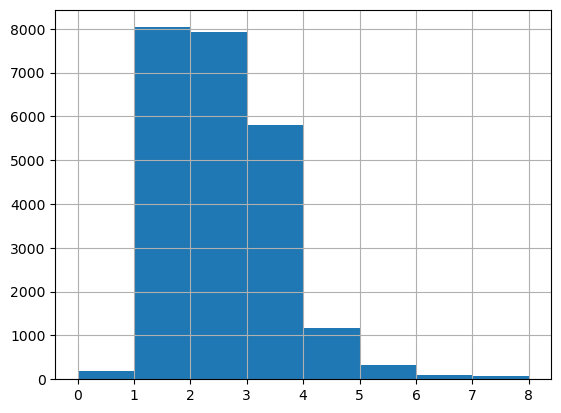

In [65]:
data['rooms'].hist(bins=8, range=(0,8))

Больше всего в датасете 2-х и 3-х комнатных квартир. 

<Axes: >

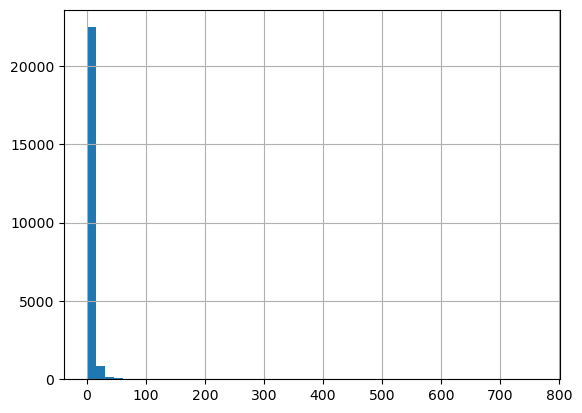

In [66]:
data['last_price_ml'].hist(bins=50)

В столбце с ценами на квартиры также есть аномально большие значения, которые сильно отличаются от медианного. Поэтому надо найти их и убрать их из гистограммы.

In [67]:
data['last_price_ml'].describe()

count    23650.000000
mean         6.541127
std         10.896399
min          0.012190
25%          3.400000
50%          4.650000
75%          6.799000
max        763.000000
Name: last_price_ml, dtype: float64

<Axes: >

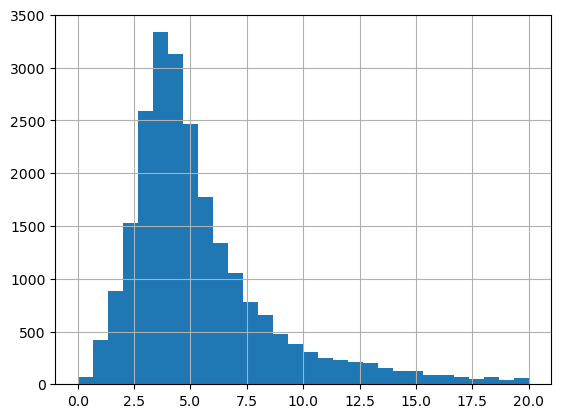

In [68]:
data['last_price_ml'].hist(bins=30, range=(0,20))

Больше всего в датасете квартир, которые стоят около 3,5 миллиона 

<Axes: >

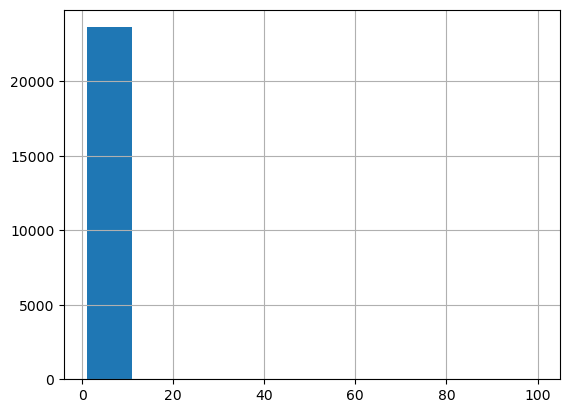

In [69]:
data['ceiling_height'].hist(bins=10)

Укрупняем гистограмму, чтобы посмотреть высоту потолков без выбивающихся значений.

<Axes: >

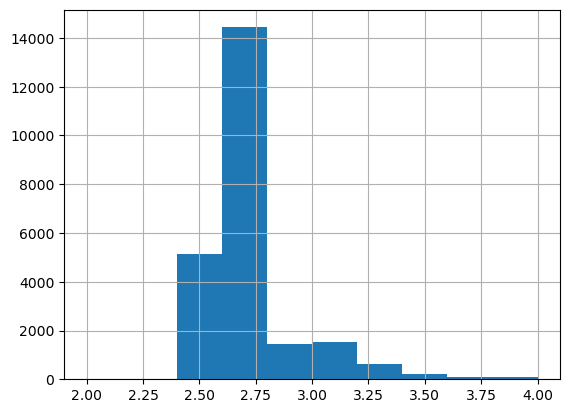

In [70]:
data['ceiling_height'].hist(bins=10, range=(2,4))

Больше всего квартир в датасете у которых высота потолка около 2,75 

<Axes: >

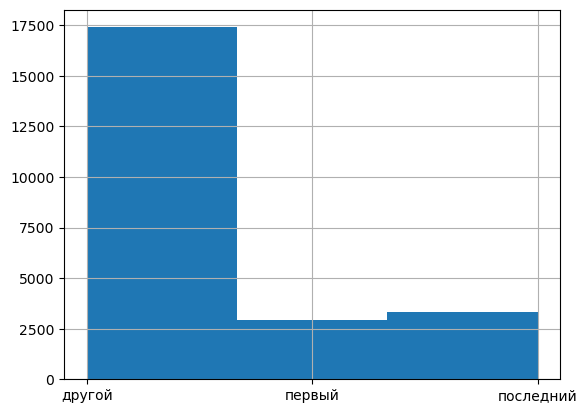

In [71]:
data['floor_type'].hist(bins=3)

Больше всего в датасете квартир которые находятся на этажах отличных от первого и последнего.

<Axes: >

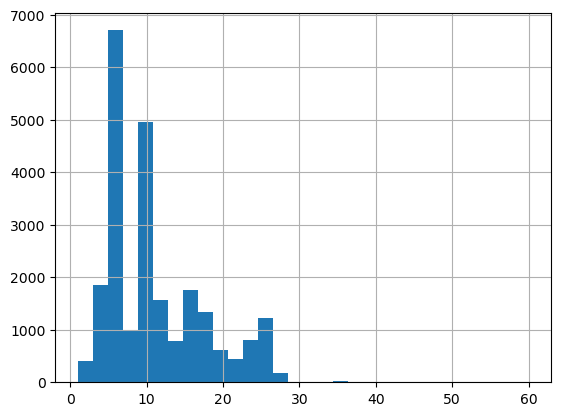

In [72]:
data['floors_total'].hist(bins=30)

In [73]:
data['floors_total'].describe()

count    23650.000000
mean        10.683552
std          6.598473
min          1.000000
25%          5.000000
50%          9.000000
75%         16.000000
max         60.000000
Name: floors_total, dtype: float64

<Axes: >

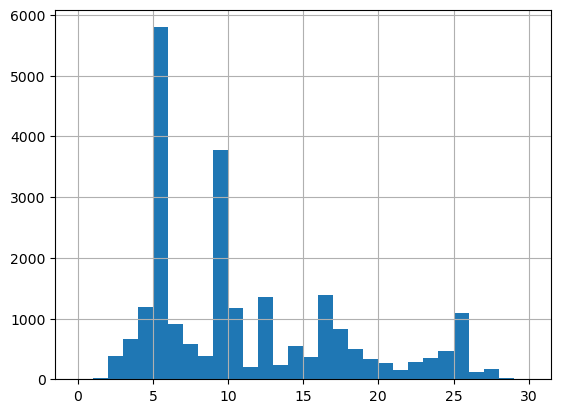

In [74]:
data['floors_total'].hist(bins=30, range=(0,30))

Больше всего квартир в датасете в пятиэтажках. Это вероятнее всего обусловлено функцией с помощью которой я заполняла пропуски. Этим же может объяснить пик на 9 этажах. 

<Axes: >

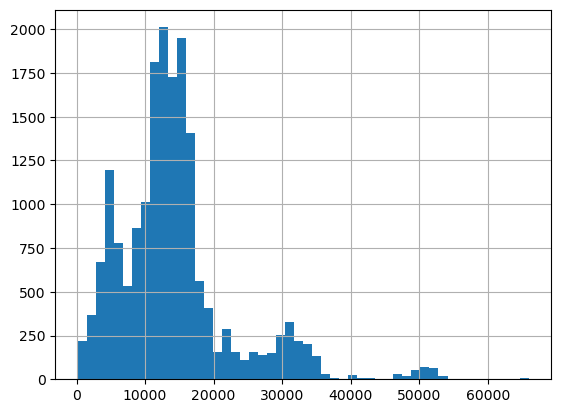

In [75]:
data['cityCenters_nearest'].hist(bins=50)

In [76]:
data['cityCenters_nearest'].describe()

count    18139.000000
mean     14197.860742
std       8606.830295
min        181.000000
25%       9241.000000
50%      13105.000000
75%      16293.000000
max      65968.000000
Name: cityCenters_nearest, dtype: float64

При укрупнении гистограммы видно, что есть два основных пика - это квартиры, которые расположенны относительно центра на рассотоянии 12000 и 15000 метров. 

<Axes: >

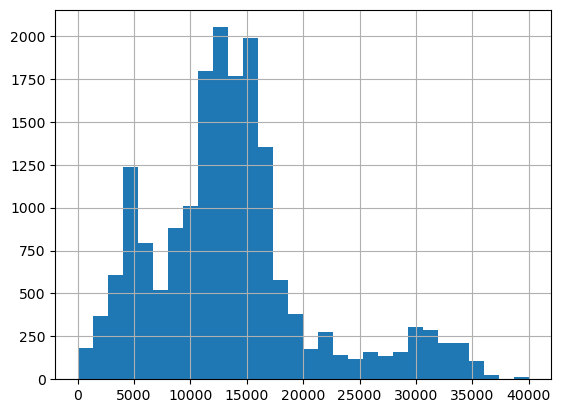

In [77]:
data['cityCenters_nearest'].hist(bins=30, range=(0,40000))

<Axes: >

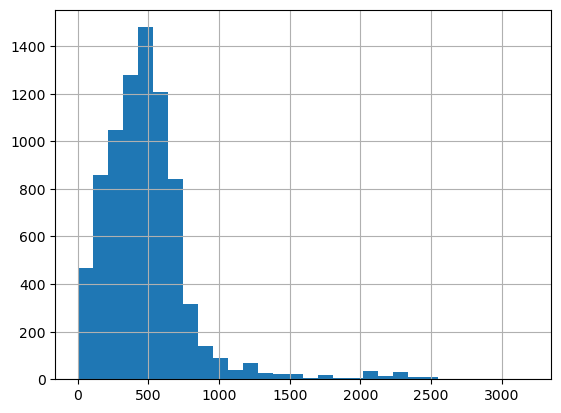

In [78]:
data['parks_nearest'].hist(bins=30)

In [79]:
data['parks_nearest'].describe()

count    8064.000000
mean      490.830729
std       342.554386
min         1.000000
25%       288.000000
50%       454.500000
75%       612.000000
max      3190.000000
Name: parks_nearest, dtype: float64

<Axes: >

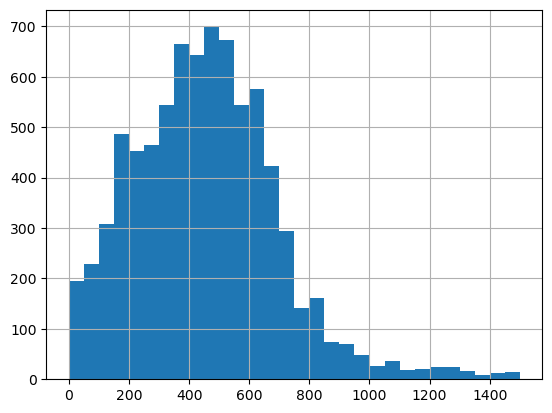

In [80]:
data['parks_nearest'].hist(bins=30, range=(0,1500))

У большинства квартир в датасете парк расположен в радиусе примерно 500 метров от квартиры.

2. Изучить, как быстро продавались квартиры (столбец `days_exposition`). Этот параметр показывает, сколько дней было размещено каждое объявление.
    - Построить гистограмму.
    - Посчитать среднее и медиану.

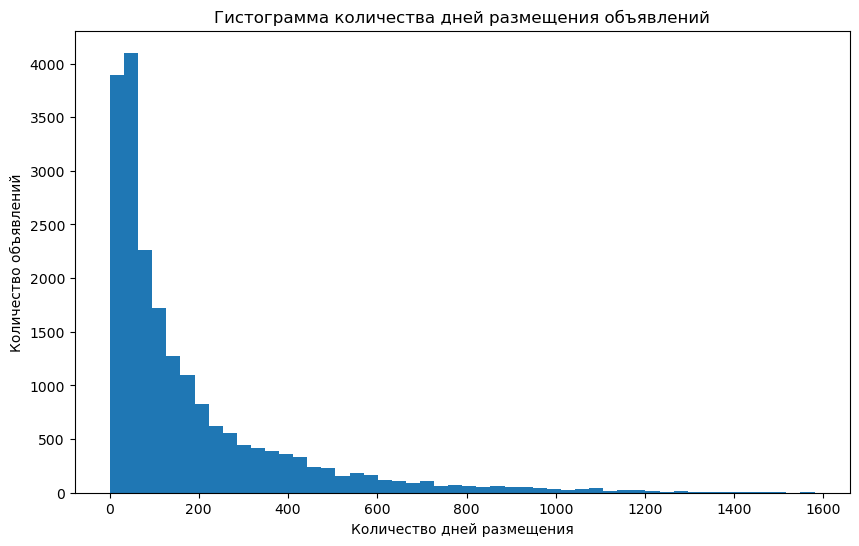

In [81]:
data['days_exposition'].plot(kind='hist', bins=50, figsize=(10, 6))
plt.xlabel('Количество дней размещения')
plt.ylabel('Количество объявлений')
plt.title('Гистограмма количества дней размещения объявлений')
plt.show()

In [82]:
mean_days = data['days_exposition'].mean()
median_days = data['days_exposition'].median()
print('В среднем квартиры продавались:', mean_days)
print("Медиана:", median_days)

В среднем квартиры продавались: 180.7531998045921
Медиана: 95.0


In [83]:
data['days_exposition'].describe()

count    20470.000000
mean       180.753200
std        219.777916
min          1.000000
25%         45.000000
50%         95.000000
75%        231.000000
max       1580.000000
Name: days_exposition, dtype: float64

Продажи можно считать быстрыми, если они занимают меньше среднего значения days_exposition, а продажи, занимающие больше среднего значения, можно считать необычно долгими.

Чтобы определить нормальные, долгие и быстрые продажи, можно использовать значения квартилей. В данном случае, 25% объявлений,  были размещены менее 45 дней, это можно считать быстрыми продажами. Половина объявлений, были размещены на протяжении от 45 до 231 дня, их можно считать нормальными продажами. И объявления, которые были размещены больше 231 дня, можно считать долгими продажами. 

3. Какие факторы больше всего влияют на общую (полную) стоимость объекта?
    
    Изучить, зависит ли цена от:
    
    - общей площади;
    - жилой площади;
    - площади кухни;
    - количества комнат;
    - этажа, на котором расположена квартира (первый, последний, другой);
    - даты размещения (день недели, месяц, год).
    
    Построить графики, которые покажут зависимость цены от указанных выше параметров. 

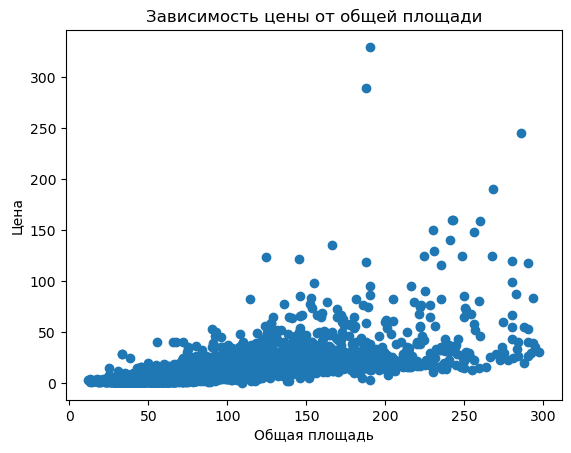

In [84]:
plt.scatter(total_area['total_area'], total_area['last_price_ml'])
plt.xlabel('Общая площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от общей площади')
plt.show()

На графике видно, что есть выбивающиеся значения цены, поэтому дальше я убираю эти выбросы и смотрю обновленный график. 

In [85]:
total_area = total_area.query('last_price_ml < 100')

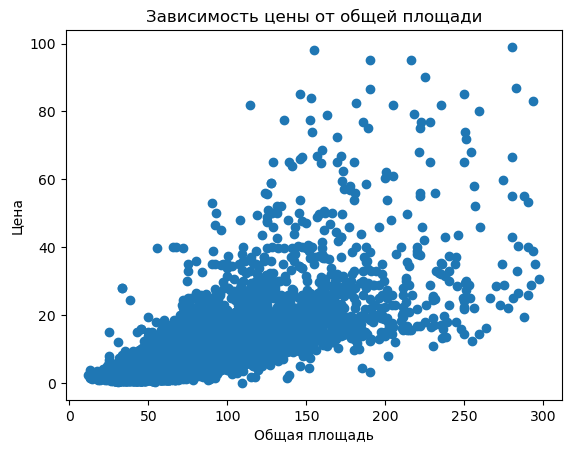

In [86]:
plt.scatter(total_area['total_area'], total_area['last_price_ml'])
plt.xlabel('Общая площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от общей площади')
plt.show()

Исходя из указанных выше данных можно предположить, что нет какой-то сильной связи между общей площадью квартиры и её ценой. Присутвует некая тенцения, когда квартиры с бОльшей площадью стоят больше, но нельзя утверждать, что цена полностью зависит от этого фактора.

Для того чтобы валидировать выводы, найду коэффициент корреляции Пирсона между общей площадью и ценой

In [87]:
total_area['total_area'].corr(total_area['last_price_ml'])

0.7532382377006719

Данное значение коэффициента корреляции Пирсона (0.753) указывает на сильную положительную линейную зависимость между величинами "общая площадь" и "цена". Это означает, что при увеличении площади квартиры, цена также увеличивается, и наоборот, при уменьшении площади квартиры, цена снижается.
Это опровергает мое первоначальное заключение о связи между этими двумя столбцами.

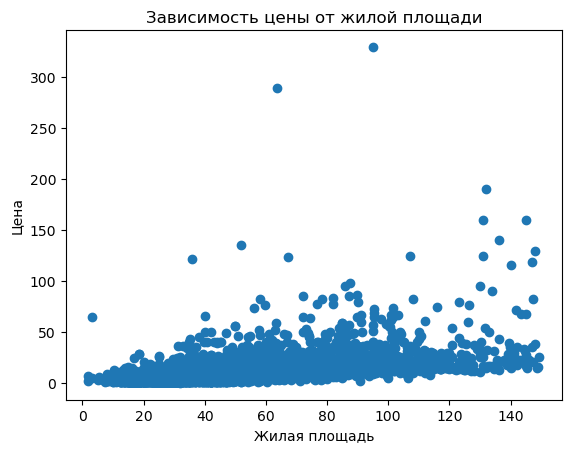

In [88]:
plt.scatter(living_area['living_area'], living_area['last_price_ml'])
plt.xlabel('Жилая площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от жилой площади')
plt.show()

Аналогично с общей площадью, убираю выбивающиеся цены для жилой площади и смотрю укрупненный график.

In [89]:
living_area = living_area.query('last_price_ml < 100')

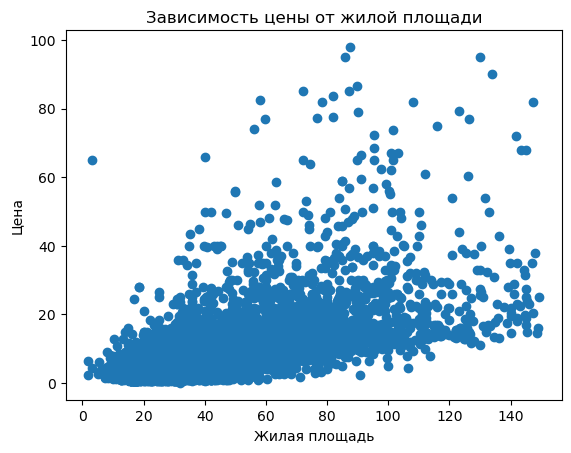

In [90]:
plt.scatter(living_area['living_area'], living_area['last_price_ml'])
plt.xlabel('Жилая площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от жилой площади')
plt.show()

В ситуации с жилой площадью зависимость выражена еще меньше, чем в случае с общей площадью. Нельзя с уверенностью утверждать, что связь между ценой и жилой площадью присутствует. 

Проверим коэффициент корреляции.

In [91]:
living_area['living_area'].corr(living_area['last_price_ml'])

0.6412241013720256

Данный коэффициент корреляции (0.635) указывает что связь между жилой площадью и ценой присутствует, однако она не так сильна, как в случае с общей площадью.

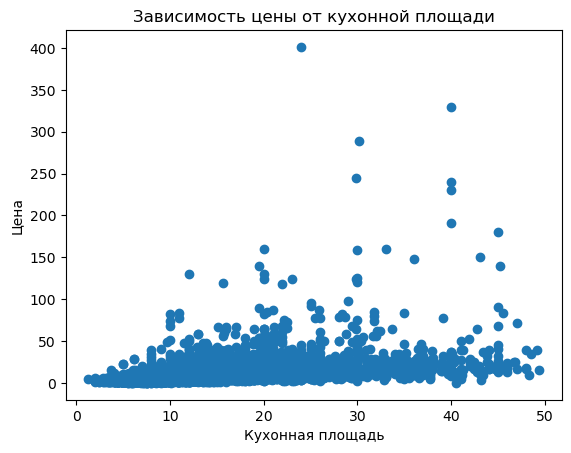

In [92]:
plt.scatter(kitchen_area['kitchen_area'], kitchen_area['last_price_ml'])
plt.xlabel('Кухонная площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от кухонной площади')
plt.show()

Здесь произвожу те же действия, что и в случае с жилой и общей площадью.

In [93]:
kitchen_area = kitchen_area.query('last_price_ml < 200')

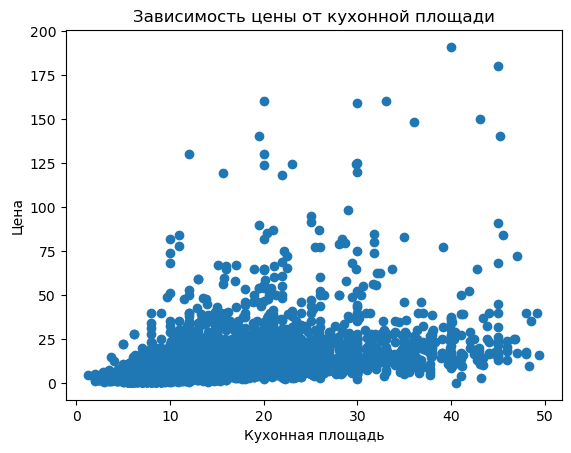

In [94]:
plt.scatter(kitchen_area['kitchen_area'], kitchen_area['last_price_ml'])
plt.xlabel('Кухонная площадь')
plt.ylabel('Цена')
plt.title('Зависимость цены от кухонной площади')
plt.show()

In [95]:
kitchen_area['kitchen_area'].corr(kitchen_area['last_price_ml'])

0.5381948613307924

Значение коэффициента корреляции Пирсона равное 0.49396 указывает на слабую положительную корреляцию между величинами площадь кухни и цена. Это означает, что с увеличением площади кухни вероятно возрастает цена недвижимости, но связь не является очень сильной.

In [96]:
price_rooms = data.pivot_table(index='rooms', values='last_price_ml', aggfunc='mean')
price_rooms

,last_price_ml
rooms,
0,3.337724
1,3.834080
2,5.590628
3,8.181798
4,13.431852
5,23.762082
6,31.709752
7,51.470069
8,50.224167


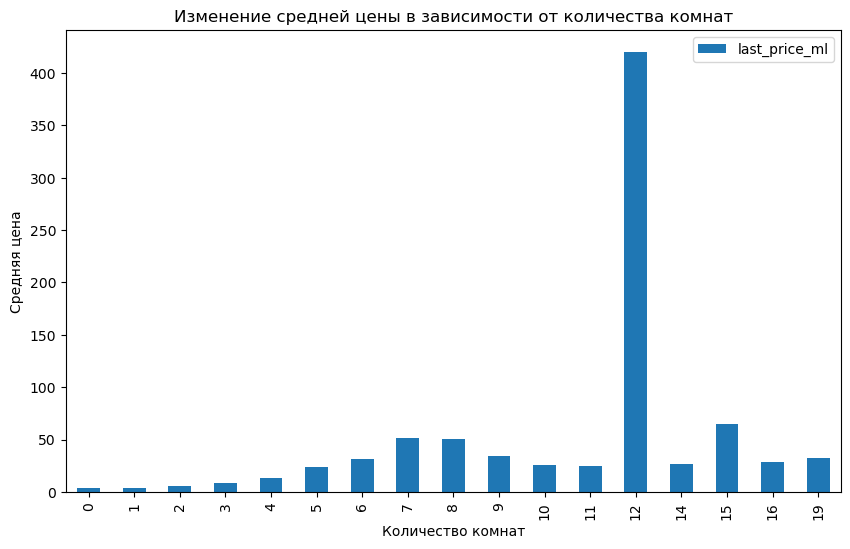

In [97]:
price_rooms.plot(kind='bar', figsize=(10, 6))
plt.title('Изменение средней цены в зависимости от количества комнат')
plt.xlabel('Количество комнат')
plt.ylabel('Средняя цена')
plt.show()

In [98]:
data['rooms'].corr(data['last_price_ml'])

0.3634206221877061

В случае с количеством комнат можно заметить стабильный рост цены влоть до 7 комнат в квартире. Если рассматривать только этот отрезок, то можно было бы говорить, что чем больше комнат в квартире, тем выше цена. Однако, начиная с 8 комнат эта зависимость прерывается и кажется что уже нет никакой связи между ценой и количеством комнат.
Если смотреть на коэффициент корреляции, то он довольно низок, чтобы можно было с уверенностью заявлять о связи между этими двумя столбцами.

In [99]:
price_floor_type = data.pivot_table(index='floor_type', values='last_price_ml', aggfunc='mean')
price_floor_type

,last_price_ml
floor_type,
другой,6.676719
первый,4.800465
последний,7.352639


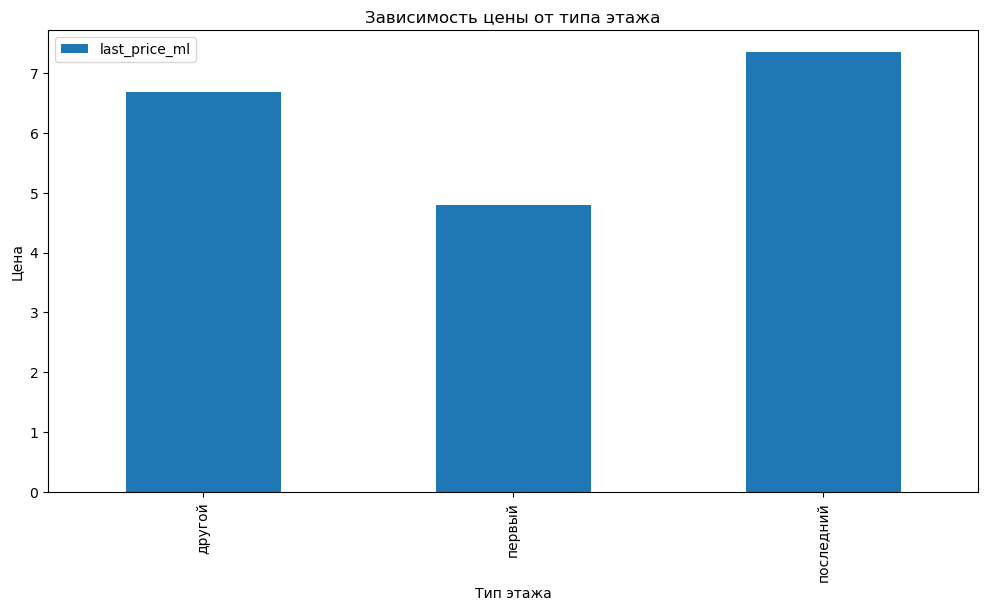

In [100]:
price_floor_type.plot(kind='bar', figsize=(12, 6))
plt.title('Зависимость цены от типа этажа')
plt.xlabel('Тип этажа')
plt.ylabel('Цена')
plt.show()

Из данных выше видно, что квартиры на последнем этаже стоят дороже, чем остальные. А квартиры, которые находятся на первом этаже самые дешевые в данном датасете.

In [101]:
price_day_of_week = data.pivot_table(index='day_of_week', values='last_price_ml', aggfunc='mean')
price_day_of_week

,last_price_ml
day_of_week,
0,6.510815
1,6.393782
2,6.626416
3,6.711767
4,6.364605
5,6.982510
6,6.249360


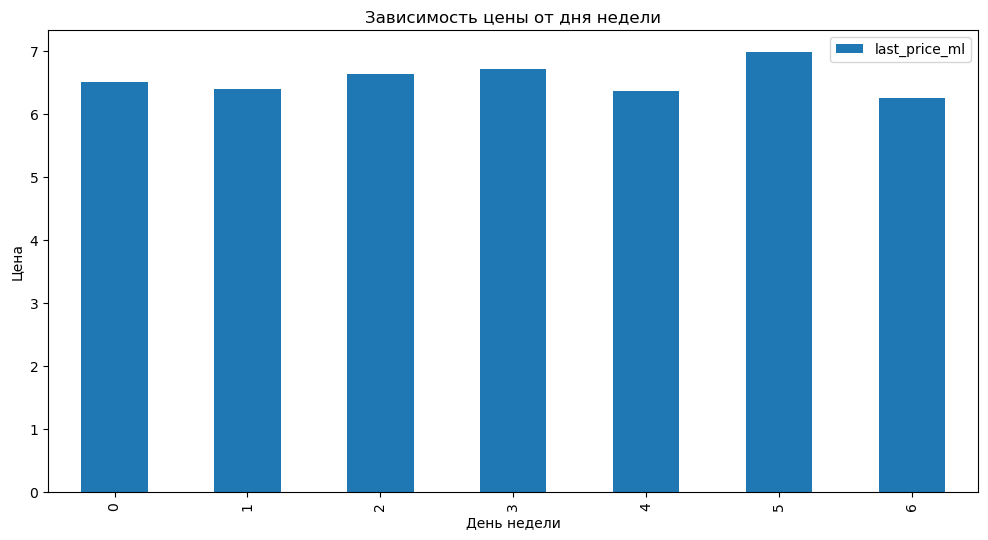

In [102]:
price_day_of_week.plot(kind='bar', figsize=(12, 6))
plt.title('Зависимость цены от дня недели')
plt.xlabel('День недели')
plt.ylabel('Цена')
plt.show()

Говоря о связи цены и дня недели, когда было опубликовано объявление, нельзя с уверенностью утверждать, что она есть. Однако, можно упомянуть, что квартиры, которые были опубликованы в субботу стоят дороже, чем квартиры опубликованные в другие дни.

In [103]:
price_month = data.pivot_table(index='month', values='last_price_ml', aggfunc='mean')
price_month

,last_price_ml
month,
1,6.666975
2,6.464463
3,6.362919
4,6.742671
5,6.594777
6,6.311184
7,6.641336
8,6.352839
9,6.828471


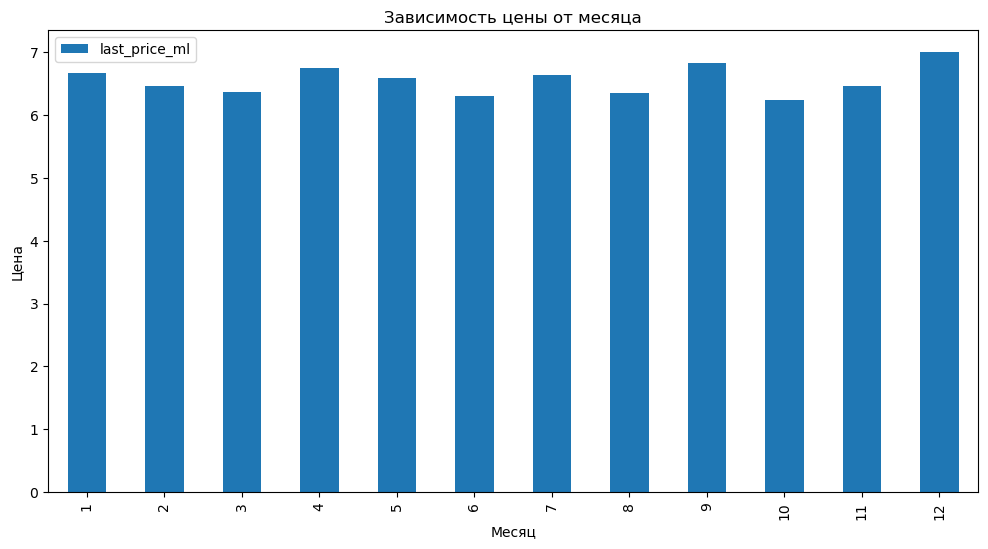

In [104]:
price_month.plot(kind='bar', figsize=(12, 6))
plt.title('Зависимость цены от месяца')
plt.xlabel('Месяц')
plt.ylabel('Цена')
plt.show()

Нет очевидной связи между ценой квартиры и месяцес публикации, однако можно заметить, что квартиры опубликованные в декабре стоят дороже, чем остальные.

In [105]:
price_year = data.pivot_table(index='year', values='last_price_ml', aggfunc='mean')
price_year

,last_price_ml
year,
2014,12.046600
2015,8.592727
2016,6.829415
2017,6.585822
2018,5.952216
2019,6.782388


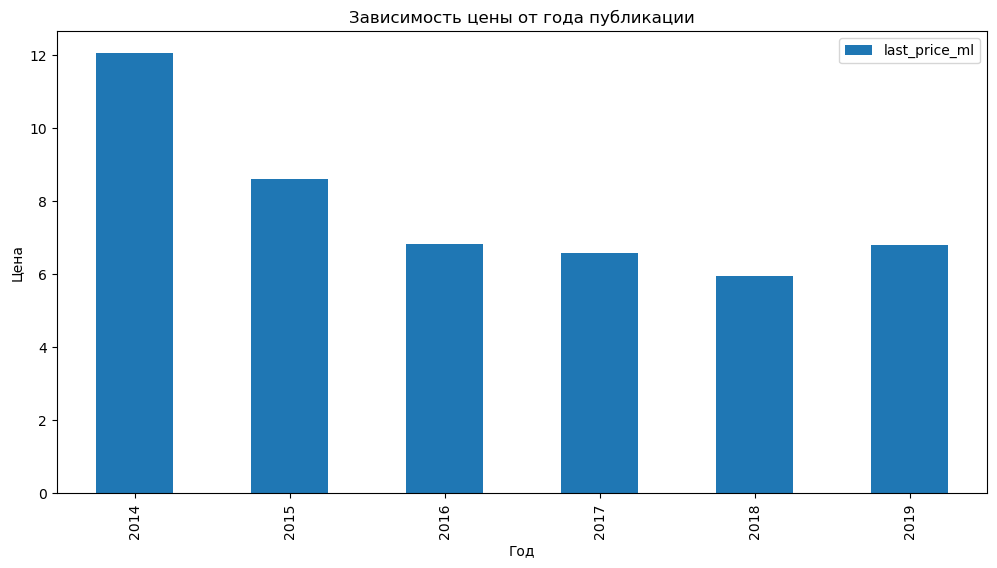

In [106]:
price_year.plot(kind='bar', figsize=(12, 6))
plt.title('Зависимость цены от года публикации')
plt.xlabel('Год')
plt.ylabel('Цена')
plt.show()

В 2014 году можно заметить самые большие цены за квартиры, которые начали сильно падать в последующие годы. Самые низкие цены за квартиры были в 2018 году, после чего цена снова начала расти. 

4. Посчитать среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений — построить сводную таблицу с количеством объявлений и средней ценой квадратного метра для этих населенных пунктов. Выделить населённые пункты с самой высокой и низкой стоимостью квадратного метра.

Для того чтобы отобрать 10 населенных пунктов с самым большим количеством объявлений, я сгруппировала данные по столбцу "locality_name" и посчитала количество объявлений в каждом населенном пункте. Затем, отсортировала результат по убыванию количества объявлений и выбрала первые 10 строчек.

In [107]:
top_localities = data.groupby('locality_name').size().nlargest(10).index
top_localities

Index(['Санкт-Петербург', 'Мурино', 'Кудрово', 'Шушары', 'Всеволожск',
       'Пушкин', 'Колпино', 'Парголово', 'Гатчина', 'Выборг'],
      dtype='object', name='locality_name')

In [108]:
pivot_table = data[data['locality_name'].isin(top_localities)].pivot_table(index='locality_name', values=['last_price', 'sqrm_price'], aggfunc={'last_price': 'count', 'sqrm_price': np.mean})
pivot_table = pivot_table.sort_values('sqrm_price', ascending=False)
pivot_table

,last_price,sqrm_price
locality_name,,
Санкт-Петербург,15721,114849.008793
Пушкин,369,103125.819377
Кудрово,472,95324.930508
Парголово,327,90175.913089
Мурино,590,86087.512017
Шушары,440,78677.364318
Колпино,338,75424.579112
Гатчина,307,68746.146515
Всеволожск,398,68654.473970


In [109]:
print("Самая высокая стоимость квадратного метра:", pivot_table['sqrm_price'].idxmax())
print("Самая низкая стоимость квадратного метра:", pivot_table['sqrm_price'].idxmin())

Самая высокая стоимость квадратного метра: Санкт-Петербург
Самая низкая стоимость квадратного метра: Выборг


После этого я решила посмотреть данные по всем населенным пунктам в датасете.

In [110]:
summary_table = data.groupby('locality_name').agg({'sqrm_price': 'mean', 'last_price': 'count'})
summary_table = summary_table.sort_values('sqrm_price', ascending=False)
summary_table

,sqrm_price,last_price
locality_name,,
Зеленогорск,115122.799583,24
Санкт-Петербург,114849.008793,15721
Репино,104238.612500,4
Пушкин,103125.819377,369
Сестрорецк,101757.616831,183
...,...,...
Совхозный,12629.130000,2
Выскатка,12335.480000,2
Вахнова Кара,11688.310000,1


In [111]:
print("Самая высокая стоимость квадратного метра:", summary_table.index[0])
print("Самая низкая стоимость квадратного метра:", summary_table.index[-1])

Самая высокая стоимость квадратного метра: Зеленогорск
Самая низкая стоимость квадратного метра: Старополье


5. Ранее я посчитала расстояние до центра в километрах. Теперь надо выделить квартиры в Санкт-Петербурге с помощью столбца `locality_name` и вычислить среднюю цену каждого километра. Описать, как стоимость объектов зависит от расстояния до центра города — построить график изменения средней цены для каждого километра от центра Петербурга.

Сначала я найду строки в таблице, где значение столбца 'locality_name' равно "Санкт-Петербург".

In [112]:
spb_flats = data.query('locality_name == "Санкт-Петербург"')

Теперь я создам новый столбец 'price_per_km', разделив столбец 'last_price' на столбец 'distance_to_center'. После я буду группировать данные по столбцу 'distance_to_center' и вычислять среднее значение столбца 'price_per_km' для каждой группы.

In [113]:
spb_flats['price_per_km'] = spb_flats['last_price'] / spb_flats['distance_to_center']

C:\Users\linda\AppData\Local\Temp\ipykernel_11720\3092009273.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  spb_flats['price_per_km'] = spb_flats['last_price'] / spb_flats['distance_to_center']


In [114]:
price_per_km = spb_flats.groupby('distance_to_center')['price_per_km'].mean()

В качестве завершения я построю график изменения средней цены для каждого километра.

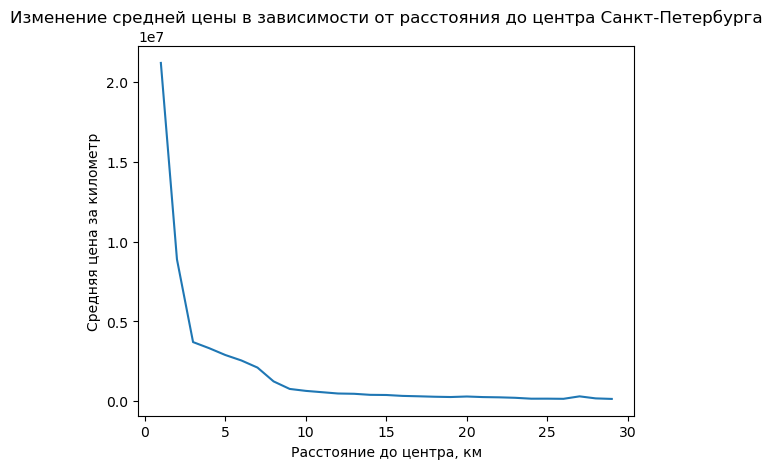

In [115]:
plt.plot(price_per_km)
plt.xlabel('Расстояние до центра, км')
plt.ylabel('Средняя цена за километр')
plt.title('Изменение средней цены в зависимости от расстояния до центра Санкт-Петербурга')
plt.show()

Как можно заметить из графика, цена за квартиру сильно зависит от расстояния квартиры до центра, если это расстояние не больше 10 км. После этого цена практически не изменяется при изменении расстояния. 

In [116]:
spb_flats_pivot = spb_flats.pivot_table(index='distance_to_center', values='last_price_ml', aggfunc='mean')
spb_flats_pivot

,last_price_ml
distance_to_center,
0.0,31.449116
1.0,21.206721
2.0,17.788320
3.0,11.126581
4.0,13.304280
5.0,14.499121
6.0,15.338418
7.0,14.775153
8.0,9.957717


Text(0.5, 1.0, 'Изменение средней цены в зависимости от расстояния до центра Санкт-Петербурга')

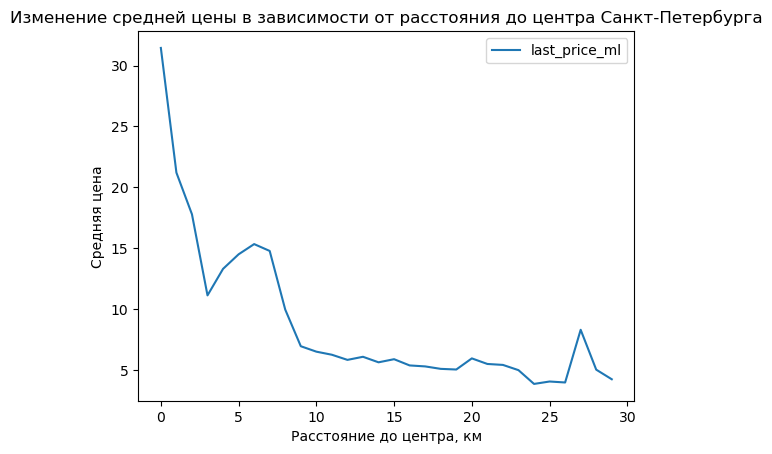

In [117]:
spb_flats_pivot.plot(kind='line')
plt.xlabel('Расстояние до центра, км')
plt.ylabel('Средняя цена')
plt.title('Изменение средней цены в зависимости от расстояния до центра Санкт-Петербурга')

Общий тренд показывает, что с увеличением расстояния до центра города, цены на квартиры снижаются, но есть некоторые колебания и выбросы в данных. Возможно, это связано с другими факторами, такими как состояние квартиры, площадь, количество комнат и т. д.

Существует некоторое пороговое значение расстояния до центра, после которого цены на квартиры стабилизируются и изменения становятся более незначительными. Наиболее ярко это заметно после 9 километра.

В целом, можно сделать вывод, что цена квартиры имеет прямую зависимость от ее расстояния до центра города, причем ближе к центру - выше цена. Однако наличие выбросов и колебаний может указывать на влияние других факторов на цену квартиры.

### Общий вывод

Написать про пропуски и их возможные причины
Расписать про новые столбцы и зачем их добавили
Сколько в среднем продавались квартиры
Какие факторы более всего влияют на цену квартиры, а какие меньше
Где самые дорогие квартиры
Как на цену влияет расстояние до центра города

1. В данном датасете присутствовали пропуски в данных, которые могут быть обоснованы несколькими причинами: 
- Те данные, которые изначально должны были заполнятся пользователями. Здесь причинами пропусков могут быть человеческими (например, пользователь по личным причинам не заполнил поле) или техническими (данные потерялись при выгрузке или объединении таблиц)
- Те данные, которые должны были заполняться сервисом автоматически. Здесь вероятнее всего есть техническая ошибка. Например, в случае с расстоянием до центра или ближайши парков и озер, сервис возможно не смог верно определить местоположении квартиры из-за чего эти данные были не заполнены изначально. Или же эти данные могли потеряться при выгрузке данных.

2. Для упрощения работы с данными и более качественного анализа были добавлены новые столбцы:
- цена за квартиру в миллионах, чтобы не пришлось обрабатывать большие числа
- цена одного квадратного метра 
- день недели публикации объявления
- месяц публикации объявления
- год публикации объявления
- тип этажа квартиры (значения — «первый», «последний», «другой»)
- расстояние до центра города в километрах

3. Общая характеристика квартир в датасете:
- В ходе проведенного анализа данных о квартирах были получены следующие результаты: средняя общая площадь квартиры составляет около 50 квадратных метров. Наиболее распространенный размер жилой площади составляет 20 квадратных метров, что означает, что значительная часть общей площади приходится на другие помещения, включая кухню, коридоры и санузлы. При анализе площади кухни было обнаружено, что чаще всего она составляет 6 или 9 квадратных метров.

- Большинство квартир в рассматриваемом датасете представляют собой 2-3-комнатные квартиры со средней стоимостью около 3,5 миллионов рублей. Этот показатель может варьироваться в зависимости от различных факторов, включая географическое расположение, общую и жилую площадь, этажность здания и другие характеристики квартиры.

- Высота потолков в большинстве квартир составляет около 2,75 метров, что является стандартом для многих жилых зданий. Большая часть квартир расположена в пятиэтажных зданиях, что может быть связано с историческими особенностями строительства жилья в определенных географических районах.

- В отношении географического расположения большинство квартир находятся на расстоянии 12000 или 15000 метров от центра города. Это может быть связано с современными трендами в сфере градостроительства, когда активное строительство жилья происходит на окраинах городов, где больше свободного пространства и легче получить разрешения на строительство.

- Также в ходе анализа было выяснено, что ближайший парк расположен в радиусе примерно 500 метров от большинства квартир. Это указывает на то, что жители имеют достаточно удобный доступ к зонам отдыха и зеленым зонам, что улучшает качество жизни и делает проживание в этих квартирах более привлекательным.

4. Как быстро продавались квартиры
В общем, из анализа данных видно, что среднее время продажи квартиры составляет около 180 дней, однако медианное значение составляет всего 95 дней. Это говорит о том, что большинство квартир продаются быстрее, чем в среднем.

На основании значений квартилей можно сделать вывод, что 25% объявлений были размещены менее 45 дней, что можно считать быстрыми продажами. Половина всех объявлений была размещена на протяжении 45-231 дня, что можно считать нормальным временем продажи. И наконец, объявления, которые были размещены более 231 дня, можно считать долгими продажами.

Таким образом, на основе анализа данных можно сказать, что большинство квартир продается достаточно быстро и нормальные времена продажи составляют от 45 до 231 дня.

5. Зависимость цены квартиры от других характеристик:
- Анализ показал, что коэффициент корреляции Пирсона (0.753) указывает на сильную положительную линейную зависимость между "общей площадью" и "ценой". Это означает, что по мере увеличения площади квартиры, цена на нее также увеличивается. Наоборот, при уменьшении площади квартиры, цена снижается.

- В случае жилой площади, коэффициент корреляции (0.635) указывает на наличие связи между жилой площадью и ценой, однако эта связь не такая сильная, как в случае с общей площадью.

- Что касается площади кухни, коэффициент корреляции Пирсона (0.494) указывает на слабую положительную корреляцию между величинами "площадь кухни" и "цена". Это означает, что с увеличением площади кухни вероятно возрастает цена недвижимости, но связь не является очень сильной.

- В отношении количества комнат, данные показывают стабильный рост цены до 7 комнат в квартире. Если рассматривать только этот диапазон, можно было бы говорить о том, что чем больше комнат в квартире, тем выше цена. Однако, начиная с 8 комнат эта зависимость прерывается и кажется, что нет сильной связи между ценой и количеством комнат. Коэффициент корреляции (0.363) довольно низок, что подтверждает наличие слабой связи между количеством комнат и ценой.

- Данные анализа также указывают на то, что квартиры, расположенные на последнем этаже, обычно стоят дороже, чем квартиры на других этажах. В то же время, квартиры на первом этаже обычно являются самыми дешевыми в данном датасете.

- В отношении связи между ценой квартиры и днем недели публикации объявления, нет явной зависимости. Однако, стоит отметить, что квартиры, объявления о продаже которых были опубликованы в субботу, обычно стоят дороже, чем квартиры, объявления о продаже которых были опубликованы в другие дни недели.

- Также не наблюдается очевидной связи между ценой квартиры и месяцем публикации объявления. Тем не менее, можно заметить, что квартиры, объявления о продаже которых были опубликованы в декабре, в среднем стоят дороже, чем квартиры, объявления о продаже которых были опубликованы в другие месяцы.

- По данным за 2014 год, цены на квартиры были самыми высокими. Однако затем наблюдалось снижение цен, которое продолжалось до 2018 года, когда были зафиксированы самые низкие цены. После 2018 года цены снова начали расти.

6. Средняя стоимость квадратного метра жилья в различных населенных пунктах была исследована для данного датасета. Это было сделано для анализа разницы в стоимости жилья и понимания, в каких географических зонах стоимость жилья наиболее высока или низкая.

Для начала, я сосредоточилась на 10 наиболее популярных населенных пунктах, чтобы представить общую картину. Результаты были следующими:

- Самая высокая стоимость квадратного метра была зарегистрирована в Санкт-Петербурге, что, вероятно, связано с высоким спросом на жилье в этом крупном городе.
- Самая низкая стоимость квадратного метра была отмечена в Выборге, что может быть связано с более низким спросом или большим количеством доступного жилья.

Однако, чтобы получить более полное представление, было решено расширить выборку и проанализировать данные по всем населенным пунктам в датасете. Результаты были несколько отличными:

- Самая высокая стоимость квадратного метра была замечена в Зеленогорске. Это может быть связано с различными факторами, такими как особенности местности, уровень жизни, доступные удобства и т.д.
- Самая низкая стоимость квадратного метра была в Старополье. Это может быть связано с меньшим спросом, большим количеством доступного жилья или другими похожими факторами.

В целом, эти данные важны для понимания того, как стоимость жилья может колебаться в зависимости от географического положения и других факторов.

7. Зависимость цены квартиры от удаленности её от центра: 
- Как можно увидеть из исследования, цена на квартиру значительно зависит от её расположения относительно центра города. Особенно заметно это в случаях, когда расстояние до центра не превышает 10 километров. В этих пределах, чем ближе квартира к центру, тем выше её стоимость. Это может быть объяснено большим спросом на жилье в центре города, более развитой инфраструктурой и престижностью такого расположения.

- Однако, интересно отметить, что после отметки в 10 километров, цена на квартиру практически не изменяется при дальнейшем увеличении расстояния. Другими словами, квартира, расположенная в 15 километрах от центра, может стоить примерно столько же, сколько и квартира в 11 километрах. Это может быть связано с тем, что за пределами центра города ценность расположения уже не играет столь значительной роли, и другие факторы, такие как размер квартиры, её планировка и состояние, становятся более важными в определении цены.

<b>Рекомендации:</b>
При построении алгоритма для отслеживания мошеннической деятельности стоит обратить внимание на несколько параметров: общую площадь квартиры, жилую площадь, этаж, удаленность от центра и количество комнат. 
Также стоит учитывать населенный пункт, в котором находится недвижимость. 
В целом данные в таблице нормально распределенны, поэтому выбросы быстро становятся заметны при близком рассмотрении отдельных столбцов, так что вычислить объявления цена на которые аномальна высока (или низка) становится доступно.  